In [1]:
import json, sys
from pathlib import Path
import pandas as pd
from IPython.display import Image, display
sys.path.insert(0, str(Path.cwd().parent / 'python'))
from analysis_common import analytical_src, segment_metrics
from config import AGGREGATE_DIR, AUDIT_DIR, CLEAN_PARQUET, DOCS_DIR, STATS_DIR, VISUALS_DIR, connect
pd.set_option('display.max_columns', 40, 'display.width', 180, 'display.float_format', '{:,.4f}'.format)
con = connect(); src = analytical_src()
kpi = json.loads((AGGREGATE_DIR / 'portfolio_kpis.json').read_text())
fin = json.loads((AGGREGATE_DIR / 'financial_totals.json').read_text())
show = lambda name: display(Image(filename=str(VISUALS_DIR / f'{name}.png')))
csv = lambda name: pd.read_csv(AGGREGATE_DIR / f'{name}.csv')

# 5. Financial Analysis
Reported cash and calculated estimates (`python/financial_analysis.py`). None of these is an accounting profit or loss.

In [2]:
pd.Series(fin).to_frame('value')

,value
funded,"34,004,208,600.0000"
funded_inv,"33,963,004,960.8061"
total_payments,"27,314,649,582.6223"
principal_received,"21,489,393,643.5810"
interest_received,"5,496,560,266.0599"
late_fees,"3,432,718.1922"
recoveries_all,"325,262,956.8629"
fees_all,"54,216,619.1961"
outstanding,"9,510,384,856.4395"
co_funded,"4,177,988,425.0000"


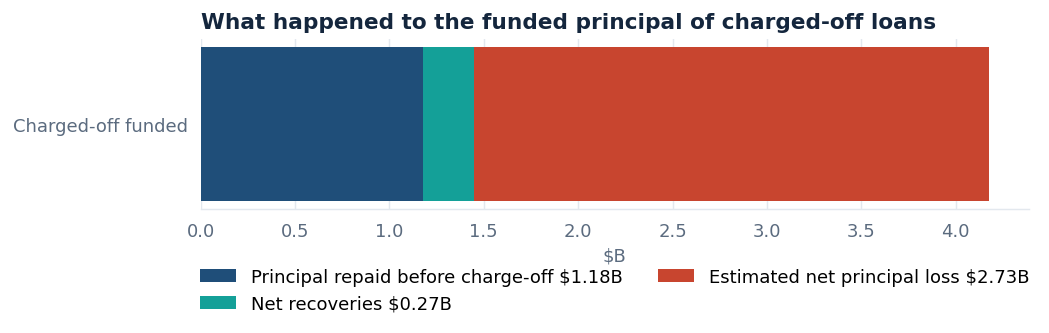

In [3]:
show('e_chargeoff_composition')
assert abs(fin['co_principal_received'] + fin['net_recoveries'] + fin['est_net_loss'] - fin['co_funded']) < 1

In [4]:
csv('cashflow_by_status')

,status_clean,funded,total_payments,principal,interest,recoveries,outstanding
0,Fully Paid,"15,210,022,825.0000","17,716,047,296.9844","15,210,022,797.3397","2,505,136,348.6201",0.0000,0.0000
1,Current,"14,002,818,250.0000","7,024,334,312.9152","4,877,056,940.1400","2,146,520,063.5000",0.0000,"9,125,761,309.8596"
2,Charged Off,"4,177,988,425.0000","2,226,645,112.7751","1,178,403,997.8500","722,189,132.3600","324,810,542.5454",0.0000
3,Late (31-120 days),"363,792,975.0000","190,737,266.6654","119,546,608.9800","70,890,392.3300",0.0000,"244,246,366.3400"
4,In Grace Period,"149,085,700.0000","89,005,556.4200","57,041,338.4800","31,819,199.5000",0.0000,"92,044,361.5200"
5,Late (16-30 days),"75,633,975.0000","42,927,276.6977","27,684,089.3700","15,153,500.9700",0.0000,"47,949,885.6300"
6,Policy Exception - Fully Paid,"17,254,600.0000","20,952,170.0673","17,254,598.6100","3,692,286.0600",0.0000,0.0000
7,Policy Exception - Charged Off,"7,037,825.0000","3,667,422.8175","2,192,180.9000","1,018,846.6100","452,414.3175",0.0000
8,Default,"574,025.0000","333,167.2800","191,091.9100","140,496.1100",0.0000,"382,933.0900"


In [5]:
csv('financial_grade')[['grade','funded_amount','unpaid_principal_at_chargeoff','recoveries','recovery_ratio','share_of_funded','share_of_unpaid_principal']]

,grade,funded_amount,unpaid_principal_at_chargeoff,recoveries,recovery_ratio,share_of_funded,share_of_unpaid_principal
0,A,"6,321,329,325.0000","114,894,432.6600","11,525,466.4553",0.1003,0.1859,0.0383
1,B,"9,401,557,325.0000","454,496,849.6800","47,306,311.9416",0.1041,0.2765,0.1515
2,C,"9,773,557,750.0000","882,902,083.7700","94,085,003.7845",0.1066,0.2874,0.2943
3,D,"5,096,087,575.0000","722,507,314.3800","77,989,289.2320",0.1079,0.1499,0.2409
4,E,"2,365,386,850.0000","511,067,356.7900","57,762,377.2332",0.1130,0.0696,0.1704
5,F,"798,480,275.0000","233,523,455.9700","27,067,286.0188",0.1159,0.0235,0.0779
6,G,"247,809,500.0000","80,192,933.9000","9,074,807.8800",0.1132,0.0073,0.0267


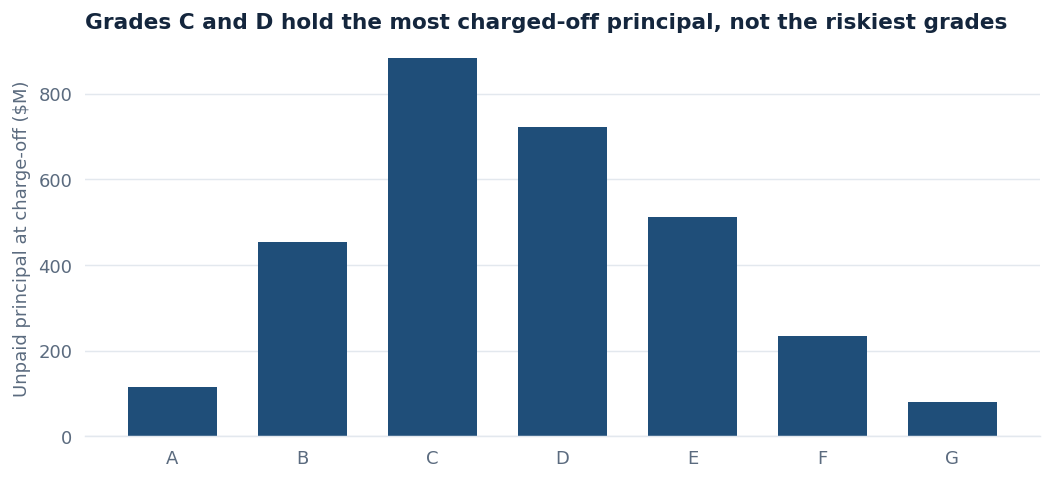

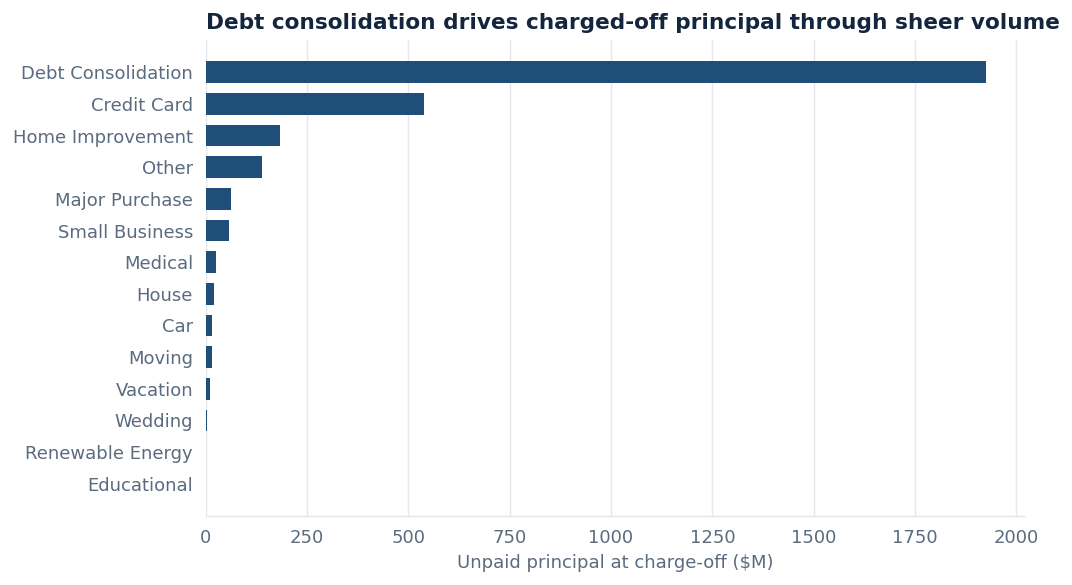

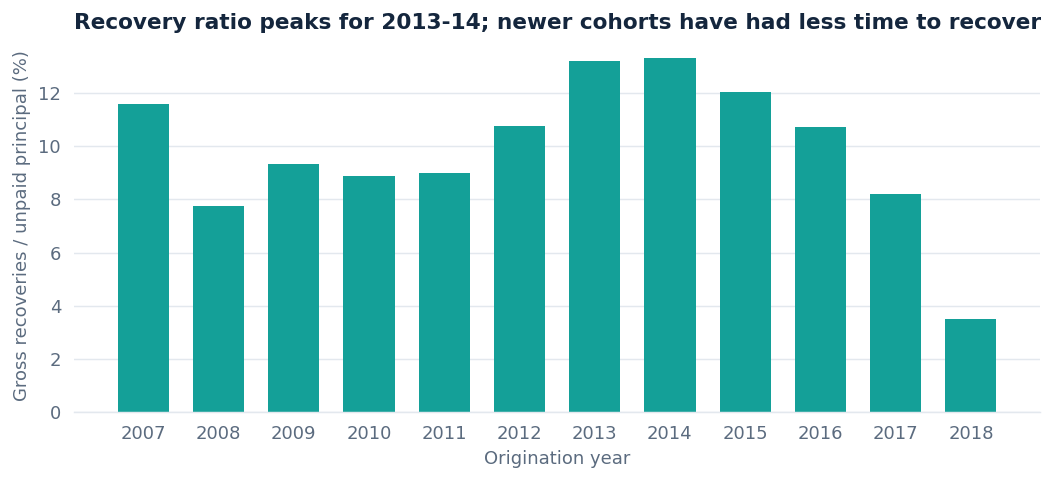

In [6]:
show('e_unpaid_principal_by_grade'); show('e_unpaid_principal_by_purpose'); show('e_recovery_ratio_by_year')

In [7]:
csv('recoveries_by_settlement')

,debt_settlement_flag,loans,unpaid,recoveries,fees,zero_recovery,recovery_ratio
0,Y,33271,"326,415,840.7700","83,761,928.9500","15,074,190.1584","3,949.0000",0.2566
1,N,235288,"2,673,168,586.3800","241,048,613.5954","39,047,496.1297","79,926.0000",0.0902
